In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import datetime
import warnings
import sidrapy
from bcb import sgs, Expectativas

# === Settings and Dates ===

warnings.filterwarnings('ignore')
np.random.seed(42)
initial_date = '2002-01-01'
DATA_FINAL = datetime.datetime.now().strftime('2026-07-31')

# === Data Extraction ===

print("Initiating data extraction...")

codes_sgs = {
    'IPCA_Mensal': 433,
    'Selic_Meta': 432,
    'IBC_Br': 24363,
    'Dolar_PTAX': 1
}

def all_sgs(code, start_date):
    start = pd.to_datetime(start_date)
    end = pd.Timestamp.today()
    
    chunks = []
    current_start = start

    while current_start < end:
    # Jumping t years to ignore the time limit

        current_end = min(current_start + pd.DateOffset(years=5), end)
        
        d_start_str = current_start.strftime('%Y-%m-%d')
        d_end_str = current_end.strftime('%Y-%m-%d')
        print(f"   -> Downloading data: {d_start_str} until {d_end_str}...")
        
        # Downloading data group
        chunk = sgs.get(code, start=d_start_str, end=d_end_str)
        chunks.append(chunk)
        
        # Updating the data for the new data group
        current_start = current_end + pd.Timedelta(days=1)
        
        # Concat all data in only one DataFrame
        df_final = pd.concat(chunks)

        # Removing duplicates
        df_final = df_final[~df_final.index.duplicated(keep='first')]
    
    return df_final

# Execute the functions: 
df_sgs = all_sgs(codes_sgs, initial_date)
df_sgs = df_sgs.dropna()
display(df_sgs)

Initiating data extraction...
   -> Downloading data: 2002-01-01 until 2007-01-01...
   -> Downloading data: 2007-01-02 until 2012-01-02...
   -> Downloading data: 2012-01-03 until 2017-01-03...
   -> Downloading data: 2017-01-04 until 2022-01-04...
   -> Downloading data: 2022-01-05 until 2026-07-12...


,IPCA_Mensal,Selic_Meta,IBC_Br,Dolar_PTAX
Date,,,,
2003-04-01,0.97,26.50,71.43536,3.3359
2003-07-01,0.20,26.00,72.04189,2.8443
2003-08-01,0.34,24.50,70.93748,3.0006
2003-09-01,0.78,22.00,71.91584,2.9840
2003-10-01,0.29,20.00,73.44254,2.9034
...,...,...,...,...
2025-08-01,-0.11,15.00,110.47825,5.5436
2025-09-01,0.48,15.00,109.57602,5.4378
2025-10-01,0.09,15.00,110.16742,5.3208


In [ ]:
from fredapi import Fred

API_KEY = ''
fred = Fred(api_key = API_KEY)
start_date = initial_date # 2002-01-01

# FED FUNDS: Federal Funds effective Rate (Monthly)
fed_funds = fred.get_series('FEDFUNDS', observation_start=start_date)
 
#CPIAUCSL: Consumer Price Index for All Urban Consumers (Monthly)
us_cpi = fred.get_series('CPIAUCSL', observation_start=start_date)

# Construction and Formatting DataFrame
df_fed = pd.DataFrame({
    'Fed_Funds': fed_funds,
    'US_CPI': us_cpi
})

df_fed.index = df_fed.index + pd.offsets.MonthBegin(0)
df_fed.index.name = 'Date'

# Drop any potential missing values from the raw series
df_fed = df_fed.dropna()
print("FRED data successfully structured!")
display(df_fed)

# Final dataset:
df_final = pd.concat([df_sgs, df_fed], axis=1).dropna()
df_final

FRED data successfully structured!


,Fed_Funds,US_CPI
Date,,
2002-01-01,1.73,177.700
2002-02-01,1.74,178.000
2002-03-01,1.73,178.500
2002-04-01,1.75,179.300
2002-05-01,1.75,179.500
...,...,...
2026-01-01,3.64,326.588
2026-02-01,3.64,327.460
2026-03-01,3.64,330.293


,IPCA_Mensal,Selic_Meta,IBC_Br,Dolar_PTAX,Fed_Funds,US_CPI
Date,,,,,,
2003-04-01,0.97,26.50,71.43536,3.3359,1.26,183.200
2003-07-01,0.20,26.00,72.04189,2.8443,1.01,183.700
2003-08-01,0.34,24.50,70.93748,3.0006,1.03,184.500
2003-09-01,0.78,22.00,71.91584,2.9840,1.01,185.100
2003-10-01,0.29,20.00,73.44254,2.9034,1.01,184.900
...,...,...,...,...,...,...
2025-07-01,0.26,15.00,113.21721,5.4511,4.33,322.169
2025-08-01,-0.11,15.00,110.47825,5.5436,4.33,323.291
2025-09-01,0.48,15.00,109.57602,5.4378,4.22,324.245


Statistics for IPCA_Mensal: Mean: 0.4420, Median: 0.4400, Std: 0.3240, Skewness: -0.1144, Kurtosis: 0.8181


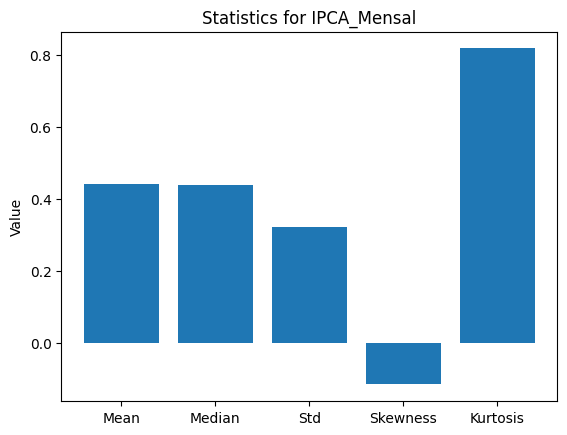

Statistics for Selic_Meta: Mean: 11.6494, Median: 11.3750, Std: 4.6049, Skewness: 0.2782, Kurtosis: 0.7069


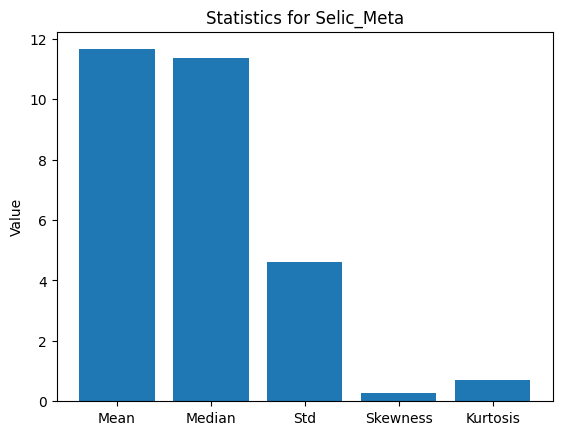

Statistics for IBC_Br: Mean: 94.3514, Median: 96.4971, Std: 10.1924, Skewness: -0.6251, Kurtosis: -0.2536


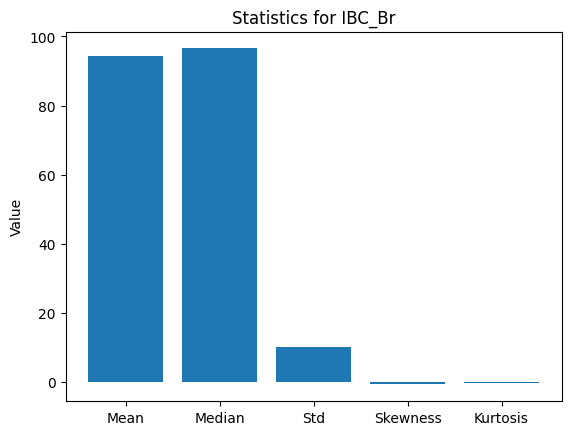

Statistics for Dolar_PTAX: Mean: 3.2677, Median: 2.9923, Std: 1.3708, Skewness: 0.4882, Kurtosis: -1.2107


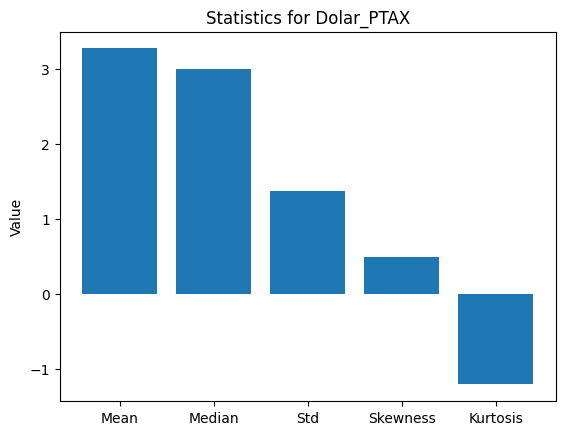

Statistics for Fed_Funds: Mean: 1.7195, Median: 1.0050, Std: 1.8794, Skewness: 0.8386, Kurtosis: -0.8186


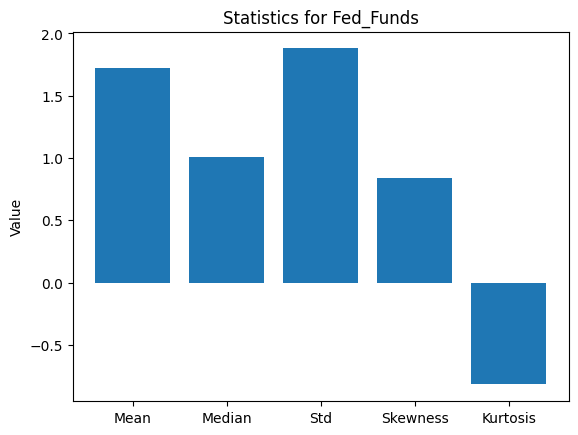

Statistics for US_CPI: Mean: 240.8725, Median: 236.3600, Std: 38.1798, Skewness: 0.6394, Kurtosis: -0.3981


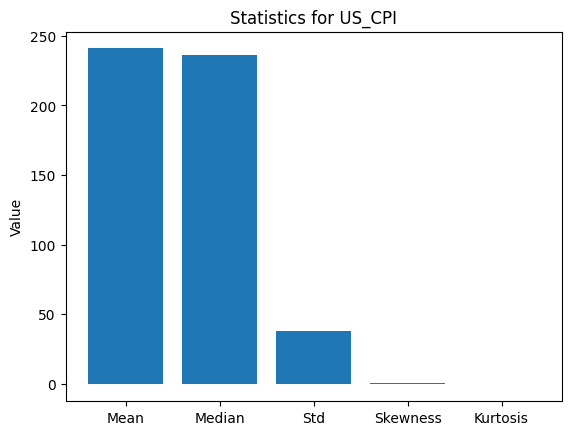

In [3]:
# === Statistical Analysis ===

for i in df_final.columns:
    stats = df_final[i].mean(), df_final[i].median(), df_final[i].std(), df_final[i].skew(), df_final[i].kurtosis()
    stat_names = ['Mean', 'Median', 'Std', 'Skewness', 'Kurtosis']
    
    print(f'Statistics for {i}: Mean: {stats[0]:.4f}, Median: {stats[1]:.4f}, Std: {stats[2]:.4f}, Skewness: {stats[3]:.4f}, Kurtosis: {stats[4]:.4f}')
    
    # Bar graph
    plt.figure()
    plt.bar(stat_names, stats)
    plt.title(f'Statistics for {i}')
    plt.ylabel('Value')
    plt.show()


In [4]:
# === Pre-processing Data ===

df_final['Selic_Ret'] = df_final['Selic_Meta'].pct_change() * 100 # Simple Returns
df_final['Fed_Ret'] = df_final['Fed_Funds'].pct_change() * 100 # Simple Returns
df_final['Selic_Diff'] = df_final['Selic_Meta'].diff() # Differentiation 

df_model = df_final.dropna()
print(df_model[['Selic_Meta', 'Selic_Ret', 'Selic_Diff']])

            Selic_Meta  Selic_Ret  Selic_Diff
Date                                         
2003-07-01       26.00  -1.886792       -0.50
2003-08-01       24.50  -5.769231       -1.50
2003-09-01       22.00 -10.204082       -2.50
2003-10-01       20.00  -9.090909       -2.00
2003-12-01       17.50 -12.500000       -2.50
...                ...        ...         ...
2025-07-01       15.00   5.263158        0.75
2025-08-01       15.00   0.000000        0.00
2025-09-01       15.00   0.000000        0.00
2025-12-01       15.00   0.000000        0.00
2026-04-01       14.75  -1.666667       -0.25

[163 rows x 3 columns]


In [5]:
# === Statistical Diagnostic Suite ===

from statsmodels.tsa.stattools import adfuller, grangercausalitytests
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox
from scipy.stats import jarque_bera
# Suppress warnings for cleaner output
warnings.filterwarnings('ignore', '.*Granger Causality.*')

print("="*60)
print("   PHASE 1: STATISTICAL DIAGNOSTIC & HYPOTHESIS TESTING")
print("="*60)

df_stats = df_model.dropna().copy()

# ---------------------------------------------------------
# 1. Stationarity Test (Augmented Dickey-Fuller)
# ---------------------------------------------------------
print("\n1. STATIONARITY TEST (ADF)")
print("H0: The series has a unit root (is non-stationary)")
for name, col in [('Selic (Level)', 'Selic_Meta'), ('Selic (Diff 1)', 'Selic_Diff'), ('Dolar PTAX', 'Dolar_PTAX')]:
    adf_result = adfuller(df_stats[col])
    p_value = adf_result[1]
    is_stationary = "Stationary (Reject H0)" if p_value < 0.05 else "Non-Stationary (Fail to reject H0)"
    print(f" - {name:15} | p-value: {p_value:.4f} | Result: {is_stationary}")

# ---------------------------------------------------------
# 2. Granger Causality (Does Macro Data drive the Selic?)
# ---------------------------------------------------------
# Note: Granger Causality requires stationary data. We use Selic_Diff and pct_change for Dolar/Fed
print("\n2. GRANGER CAUSALITY TEST (Lags = 3 months)")
print("H0: Variable X DOES NOT Granger-cause Selic_Diff")

df_granger = pd.DataFrame({
    'Selic_Diff': df_stats['Selic_Diff'],
    'Dolar_Ret': df_stats['Dolar_PTAX'].pct_change(),
    'Fed_Ret': df_stats['Fed_Funds'].pct_change(),
    'IPCA': df_stats['IPCA_Mensal']
}).dropna()

max_lag = 3
for exog in ['IPCA', 'Dolar_Ret', 'Fed_Ret']:
    print(f"\n Testing: {exog} -> Selic_Diff")
    gc_res = grangercausalitytests(df_granger[['Selic_Diff', exog]], maxlag=[max_lag], verbose=False)
    # Extract p-value for the SSR F-test at lag 3
    p_val = gc_res[max_lag][0]['ssr_ftest'][1]
    conclusion = "Causal Relationship Found! (Reject H0)" if p_val < 0.05 else "No Causality Found"
    print(f" - p-value (Lag {max_lag}): {p_val:.4f} | Conclusion: {conclusion}")

# ---------------------------------------------------------
# 3. ARCH-LM Test (Testing for Volatility Clustering)
# ---------------------------------------------------------
# Tests if the residuals of the Selic returns have changing variance over time.
print("\n3. ARCH-LM TEST (Justifying the use of EGARCH)")
print("H0: No ARCH effects (Variance is constant)")
selic_log_ret = np.log(df_stats['Selic_Meta'] / df_stats['Selic_Meta'].shift(1)).dropna()
arch_test = het_arch(selic_log_ret - selic_log_ret.mean(), nlags=3)
print(f" - p-value: {arch_test[1]:.4f}")
if arch_test[1] < 0.05:
    print(" - Conclusion: ARCH effects present (Reject H0). EGARCH modeling is MATHEMATICALLY JUSTIFIED.")
else:
    print(" - Conclusion: No ARCH effects (Fail to reject H0). EGARCH may be over-specified.")

# ---------------------------------------------------------
# 4. Normality Test (Jarque-Bera)
# ---------------------------------------------------------
print("\n4. NORMALITY TEST (Jarque-Bera on Selic Returns)")
print("H0: The data is normally distributed")
jb_test = jarque_bera(selic_log_ret)
print(f" - p-value: {jb_test[1]:.4f}")
if jb_test[1] < 0.05:
    print(" - Conclusion: Distribution is NOT Normal (Reject H0). Has fat tails. Non-linear ML (XGBoost) is JUSTIFIED.")
else:
    print(" - Conclusion: Distribution is Normal. Linear models might suffice.")
print("="*60)

   PHASE 1: STATISTICAL DIAGNOSTIC & HYPOTHESIS TESTING

1. STATIONARITY TEST (ADF)
H0: The series has a unit root (is non-stationary)
 - Selic (Level)   | p-value: 0.0991 | Result: Non-Stationary (Fail to reject H0)
 - Selic (Diff 1)  | p-value: 0.0000 | Result: Stationary (Reject H0)
 - Dolar PTAX      | p-value: 0.8965 | Result: Non-Stationary (Fail to reject H0)

2. GRANGER CAUSALITY TEST (Lags = 3 months)
H0: Variable X DOES NOT Granger-cause Selic_Diff

 Testing: IPCA -> Selic_Diff
 - p-value (Lag 3): 0.0206 | Conclusion: Causal Relationship Found! (Reject H0)

 Testing: Dolar_Ret -> Selic_Diff
 - p-value (Lag 3): 0.7801 | Conclusion: No Causality Found

 Testing: Fed_Ret -> Selic_Diff
 - p-value (Lag 3): 0.7833 | Conclusion: No Causality Found

3. ARCH-LM TEST (Justifying the use of EGARCH)
H0: No ARCH effects (Variance is constant)
 - p-value: 0.0000
 - Conclusion: ARCH effects present (Reject H0). EGARCH modeling is MATHEMATICALLY JUSTIFIED.

4. NORMALITY TEST (Jarque-Bera on 

Initiating Stationarity Test
Original: p-valor = 0.0991 the series is Non-Stationary
Diferença: p-valor = 0.0000 the series is Stationary


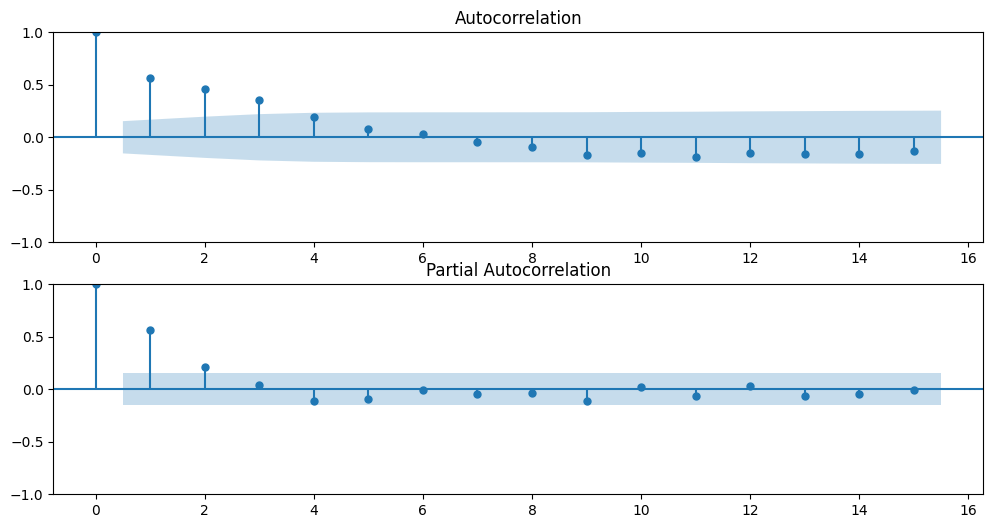

In [6]:
# === Stationarity and Autocorrelation Analysis ===
from statsmodels.tsa.stattools import adfuller 
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

print("Initiating Stationarity Test")
for name, serie in [('Original', df_model['Selic_Meta']), ('Diferença', df_model['Selic_Diff'])]:
    result = adfuller(serie.dropna())
    print(f'{name}: p-valor = {result[1]:.4f} the series is {'Stationary' if result[1] < 0.05 else 'Non-Stationary'}')

# Plot ACF/PACF test for serie diff (this will define the ARIMA model parameters)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6))
plot_acf(df_model['Selic_Diff'].dropna(), lags=15, ax=ax1)
plot_pacf(df_model['Selic_Diff'].dropna(), lags=15, ax=ax2)
plt.show()

In [7]:
# === ARIMA Model (Forecast for 12 months) ===
from statsmodels.tsa.arima.model import ARIMA

# Fit ARIMA model
model = ARIMA(df_model['Selic_Meta'], order=(1, 1, 1)) # ARIMA (p,d,q)
model_fit = model.fit()
print(model_fit.summary())

# Forecast the next 12 months:
print('Initiating Forecast for the Interest Rate for the next 12 months...')
forecast_arima = model_fit.forecast(steps=12)

                               SARIMAX Results                                
Dep. Variable:             Selic_Meta   No. Observations:                  163
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -154.847
Date:                Sun, 12 Jul 2026   AIC                            315.694
Time:                        11:52:06   BIC                            324.957
Sample:                             0   HQIC                           319.455
                                - 163                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8020      0.068     11.747      0.000       0.668       0.936
ma.L1         -0.3392      0.116     -2.923      0.003      -0.567      -0.112
sigma2         0.3948      0.021     19.107      0.0

c:\Users\henri\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\henri\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\henri\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\henri\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is ava

In [8]:
# === Applying E-GARCH Model for Volatility Forecasting ===

from arch import arch_model

# For E-GARCH model, we will use the logarithmic returns of the Selic Rate, as it is a common practice in financial time series analysis to model volatility. 
# An important information is that the E-GARCH model works better with log returns, so this is why we will use them, instead of the simple returns, previously calculated. 

df_final['Selic_Log_Ret'] = np.log(df_final['Selic_Meta'] / df_final['Selic_Meta'].shift(1)) * 100 # Log Returns
returns = df_final['Selic_Log_Ret'].dropna()

# Adjust EGARCH (1,1) with normal distribution

garch_model = arch_model(returns, vol='Garch', p=1, q=1, dist='normal')
garch_res = garch_model.fit(update_freq=5, disp='off')
print(garch_res.summary())

print('Initiating Variance forecast for the next 12 months...')
garch_forecast = garch_res.forecast(horizon=12)
vol_forecast = np.sqrt(garch_forecast.variance.iloc[-1].values)

print('n📊 Forecast Vol (standard deviation of Logarithmic Returns) for the next 12 months:')
for i, vol in enumerate(vol_forecast, 1):
    print(f'Month {i}: {vol:.4f}%')

                     Constant Mean - GARCH Model Results                      
Dep. Variable:          Selic_Log_Ret   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -560.885
Distribution:                  Normal   AIC:                           1129.77
Method:            Maximum Likelihood   BIC:                           1142.14
                                        No. Observations:                  163
Date:                Sun, Jul 12 2026   Df Residuals:                      162
Time:                        11:52:07   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu            -0.3105      0.746     -0.416      0.677 [ -1.773,  1.15

In [9]:
# === Download Focus Market Expectations (BCB) -  ===
from bcb import sgs
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# Focus series codes (median expectations)
# Source: https://www3.bcb.gov.br/sgspub/localizarseries/localizarSeries.do
focus_series = {
    'IPCA_12M': 4473,
    'SELIC_12M': 4475,
    'PIB_12M': 4476,
    'DOLAR_12M': 4477,
}

downloaded = {}
for name, code in focus_series.items():
    try:
        series = sgs.get(code, start='2002-01-01')
        if series is not None and not series.empty:
            downloaded[name] = series
            print(f"✓ Downloaded {name} (code {code}) - {len(series)} obs")
        else:
            # Fallback: try with a more recent start date
            series = sgs.get(code, start='2010-01-01')
            if series is not None and not series.empty:
                downloaded[name] = series
                print(f"✓ Downloaded {name} (code {code}) - {len(series)} obs (fallback)")
            else:
                print(f"⚠️ Could not download {name} (code {code})")
    except Exception as e:
        print(f"❌ Error downloading {name}: {e}")

if not downloaded:
    print("⚠️ No Focus data downloaded. Continuing without Focus features.")
    # Create empty dataframe to avoid errors later
    df_focus = pd.DataFrame()
else:
    # Concatenate series along columns (aligns by index automatically)
    df_focus = pd.concat(downloaded, axis=1)
    df_focus.columns = list(downloaded.keys())
    df_focus.index.name = 'Date'
    print(f"\n✅ Focus data: {df_focus.shape[0]} rows, {df_focus.shape[1]} columns")

    # Resample to monthly frequency (last available value per month)
    df_focus_monthly = df_focus.resample('MS').last()
    df_final.index = df_final.index.to_period('M').to_timestamp()
    df_focus_monthly.index = df_focus_monthly.index.to_period('M').to_timestamp()

    # Join with df_final (preserve all rows with left join)
    # Use suffixes to avoid column overlap warnings
    df_final = df_final.join(df_focus_monthly, how='left', rsuffix='_focus')

    # Forward fill missing values (for months without Focus data)
    focus_cols = list(downloaded.keys())
    df_final[focus_cols] = df_final[focus_cols].fillna(method='ffill')
    df_final[focus_cols] = df_final[focus_cols].fillna(method='bfill')

    print("✅ Focus data integrated into df_final")
    print(df_final[['Selic_Meta'] + focus_cols].tail())

✓ Downloaded IPCA_12M (code 4473) - 293 obs
✓ Downloaded SELIC_12M (code 4475) - 293 obs
✓ Downloaded PIB_12M (code 4476) - 293 obs
✓ Downloaded DOLAR_12M (code 4477) - 293 obs

✅ Focus data: 293 rows, 4 columns
✅ Focus data integrated into df_final
            Selic_Meta  IPCA_12M  SELIC_12M   PIB_12M  DOLAR_12M
Date                                                            
2025-07-01       15.00  86738.13  -20130.98  61748.91    3482.16
2025-08-01       15.00  86634.27  -20402.31  62313.91    3397.47
2025-09-01       15.00  84994.21  -19932.30  61112.18    3396.28
2025-12-01       15.00  90948.39  -21926.66  63076.33    3422.29
2026-04-01       14.75  80948.65  -18183.22  67023.73    3334.30


In [10]:
# === Data Diagnostic: Check Missing Values ===

print("=== df_final shape before feature engineering ===")
print(f"df_final shape: {df_final.shape}")
print(f"Columns: {df_final.columns.tolist()}")

# Check for missing values in key columns
key_cols = ['Selic_Meta', 'IPCA_Mensal', 'Dolar_PTAX', 'Fed_Funds']
for col in key_cols:
    if col in df_final.columns:
        null_count = df_final[col].isnull().sum()
        print(f"{col}: {null_count} missing values (out of {len(df_final)})")
    else:
        print(f"{col}: column not found")

# Check if there are any Focus columns already present
focus_cols = ['IPCA_12M', 'SELIC_12M', 'PIB_12M', 'DOLAR_12M']
for col in focus_cols:
    if col in df_final.columns:
        null_count = df_final[col].isnull().sum()
        print(f"{col}: {null_count} missing values (out of {len(df_final)})")
    else:
        print(f"{col}: column not found")

print("\n=== Date range ===")
print(f"First date: {df_final.index.min()}")
print(f"Last date: {df_final.index.max()}")

=== df_final shape before feature engineering ===
df_final shape: (164, 14)
Columns: ['IPCA_Mensal', 'Selic_Meta', 'IBC_Br', 'Dolar_PTAX', 'Fed_Funds', 'US_CPI', 'Selic_Ret', 'Fed_Ret', 'Selic_Diff', 'Selic_Log_Ret', 'IPCA_12M', 'SELIC_12M', 'PIB_12M', 'DOLAR_12M']
Selic_Meta: 0 missing values (out of 164)
IPCA_Mensal: 0 missing values (out of 164)
Dolar_PTAX: 0 missing values (out of 164)
Fed_Funds: 0 missing values (out of 164)
IPCA_12M: 0 missing values (out of 164)
SELIC_12M: 0 missing values (out of 164)
PIB_12M: 0 missing values (out of 164)
DOLAR_12M: 0 missing values (out of 164)

=== Date range ===
First date: 2003-04-01 00:00:00
Last date: 2026-04-01 00:00:00


In [11]:
# === Feature Engineering for ARIMA-XGBoost Ensemble (Antifragile Pipeline) ===

print("=== Starting Feature Engineering ===")

# 1. Extract ARIMA Residuals & EGARCH Volatility (In-Sample)
df_final['ARIMA_Pred'] = model_fit.predict()
df_final['ARIMA_Residual'] = df_final['Selic_Meta'] - df_final['ARIMA_Pred']

# Pad the EGARCH conditional volatility
volatility_padded = [np.nan] + list(garch_res.conditional_volatility)
df_final['EGARCH_Vol'] = pd.Series(volatility_padded, index=df_final.index).bfill()

# 2. Lag features for Selic (selected lags to capture inertia)
for lag in [1, 3, 6, 12]:
    df_final[f'Selic_Lag_{lag}'] = df_final['Selic_Meta'].shift(lag)
    
df_final['MA_3'] = df_final['Selic_Meta'].rolling(3).mean()
df_final['MA_6'] = df_final['Selic_Meta'].rolling(6).mean()

# 3. FIXING LOOKAHEAD BIAS (Data Vintage)
df_final['IPCA_Lag_1'] = df_final['IPCA_Mensal'].shift(1)
df_final['Fed_Lag_1'] = df_final['Fed_Funds'].shift(1)
df_final['Dolar_Lag_1'] = df_final['Dolar_PTAX'].shift(1)

if 'IBC_Br' in df_final.columns:
    df_final['IBC_Br_Lag_2'] = df_final['IBC_Br'].shift(2)
if 'IPCA_12M' in df_final.columns:
    df_final['Focus_IPCA_Lag_2'] = df_final['IPCA_12M'].shift(2)
    df_final['Focus_SELIC_Lag_2'] = df_final['SELIC_12M'].shift(2)

# 4. Structural Breaks & NEW DYNAMIC FEATURES
df_final['Crisis_2008'] = ((df_final.index >= '2008-09-01') & (df_final.index <= '2009-03-01')).astype(int)
df_final['Crisis_Covid'] = ((df_final.index >= '2020-03-01') & (df_final.index <= '2021-06-01')).astype(int)

# A. Time-aware Election Dummy (Brazil elections in Oct 2026)
df_final['Election_Period'] = ((df_final.index >= '2026-08-01') & (df_final.index <= '2026-11-01')).astype(int)

# B. Market Pricing Proxy (Yield Curve / Consensus Spread)
# Captures if the market is currently pricing a hike (positive spread) or a cut (negative spread)
if 'Focus_SELIC_Lag_2' in df_final.columns:
    df_final['Market_Expectation_Spread'] = df_final['Focus_SELIC_Lag_2'] - df_final['Selic_Meta']

# C. Dynamic Risk Proxy (Exchange Rate Volatility)
# Represents geopolitical/internal risk shocks (Tax increases, wars, etc.)
df_final['Risk_Proxy'] = df_final['Dolar_PTAX'].pct_change().rolling(3).std()

# 5. Drop all rows with any NaN
before_drop = len(df_final)
df_model_clean = df_final.dropna()
after_drop = len(df_model_clean)
print(f"Rows after dropna: {after_drop} (removed {before_drop - after_drop} rows to prevent Lookahead Bias)")

# Defining X and y (Target is ARIMA_Residual)
target = 'ARIMA_Residual'

exclude_cols = ['Date', 'Selic_Meta', 'ARIMA_Residual', 'ARIMA_Pred', 
                'Selic_Ret', 'Selic_Diff', 'Selic_Log_Ret', 'IPCA_Mensal', 
                'IBC_Br', 'Dolar_PTAX', 'Fed_Funds', 'US_CPI', 
                'IPCA_12M', 'SELIC_12M', 'PIB_12M', 'DOLAR_12M']

feature_cols = [col for col in df_model_clean.columns if col not in exclude_cols]
X = df_model_clean[feature_cols]
y = df_model_clean[target]

# Split (80/20 chronological)
split_idx = int(0.8 * len(X))
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

y_test_actual_selic = df_model_clean['Selic_Meta'].iloc[split_idx:]
arima_pred_test = df_model_clean['ARIMA_Pred'].iloc[split_idx:]

print(f"Features ({len(feature_cols)}):", feature_cols)

=== Starting Feature Engineering ===
Rows after dropna: 152 (removed 12 rows to prevent Lookahead Bias)
Features (19): ['Fed_Ret', 'EGARCH_Vol', 'Selic_Lag_1', 'Selic_Lag_3', 'Selic_Lag_6', 'Selic_Lag_12', 'MA_3', 'MA_6', 'IPCA_Lag_1', 'Fed_Lag_1', 'Dolar_Lag_1', 'IBC_Br_Lag_2', 'Focus_IPCA_Lag_2', 'Focus_SELIC_Lag_2', 'Crisis_2008', 'Crisis_Covid', 'Election_Period', 'Market_Expectation_Spread', 'Risk_Proxy']


In [ ]:
# === XGBoost with Optuna (Corrected Validation - v2) ===
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
import optuna

# Optuna requires logging set to warning to prevent console spam
optuna.logging.set_verbosity(optuna.logging.WARNING)

if len(X_train) < 15:
    raise ValueError(f"Training set too small ({len(X_train)} samples). Need at least 15 for meaningful walk-forward validation.")

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 400),
        "max_depth": trial.suggest_int("max_depth", 2, 6), # Shallower trees prevent overfitting
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 0.9),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 0.9),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-2, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 10.0, log=True),
    }
    model = XGBRegressor(**params, random_state=42, verbosity=0)
    
    # Dynamic n_splits for TimeSeriesSplit (Walk-Forward Validation)
    # Guarantees at least ~20 samples per fold to avoid the Optuna failure
    max_splits = min(5, max(2, len(X_train) // 20))
    
    tscv = TimeSeriesSplit(n_splits=max_splits)
    scores = []
    for train_idx, val_idx in tscv.split(X_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
        model.fit(X_tr, y_tr)
        preds = model.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, preds))
        scores.append(rmse)
    
    return np.mean(scores)

print("Running Optuna hyperparameter optimization...")
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30, show_progress_bar=True)

best_params = study.best_params
print("Best parameters for Residual Model:", best_params)

# Train final XGBoost model on the residuals
xgb_residual_model = XGBRegressor(**best_params, random_state=42, verbosity=0)
xgb_residual_model.fit(X_train, y_train)

# Evaluate the Hybrid Ensemble (ARIMA base + XGBoost residuals)
xgb_res_pred = xgb_residual_model.predict(X_test)

# The final prediction is the ARIMA base prediction + the non-linear predicted residual
y_pred_ensemble = arima_pred_test + xgb_res_pred

rmse_ensemble = np.sqrt(mean_squared_error(y_test_actual_selic, y_pred_ensemble))
mae_ensemble = mean_absolute_error(y_test_actual_selic, y_pred_ensemble)
r2_ensemble = r2_score(y_test_actual_selic, y_pred_ensemble)

print(f"\nHybrid Ensemble (ARIMA + XGBoost) - Out-of-Sample Results:")
print(f"RMSE: {rmse_ensemble:.4f}, MAE: {mae_ensemble:.4f}, R²: {r2_ensemble:.4f}")

Running Optuna hyperparameter optimization...


  0%|          | 0/30 [00:00<?, ?it/s]

Best parameters for Residual Model: {'n_estimators': 319, 'max_depth': 6, 'learning_rate': 0.04602756100887958, 'subsample': 0.6198941037282223, 'colsample_bytree': 0.659171335648565, 'reg_alpha': 4.264631064188599, 'reg_lambda': 9.142720607205655}

Hybrid Ensemble (ARIMA + XGBoost) - Out-of-Sample Results:
RMSE: 0.8205, MAE: 0.5301, R²: 0.8698


In [13]:
# === Ridge Regression with Optuna ===
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error
import numpy as np
import optuna

scaler_ridge = StandardScaler()
X_train_scaled = scaler_ridge.fit_transform(X_train)
X_test_scaled = scaler_ridge.transform(X_test)

def objective_ridge(trial):
    alpha = trial.suggest_float('alpha', 1e-3, 100.0, log=True)
    model = Ridge(alpha=alpha)
    tscv = TimeSeriesSplit(n_splits=5)
    scores = []
    for train_idx, val_idx in tscv.split(X_train_scaled):
        X_tr, X_val = X_train_scaled[train_idx], X_train_scaled[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
        model.fit(X_tr, y_tr)
        preds = model.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, preds))
        scores.append(rmse)
    return np.mean(scores)

study_ridge = optuna.create_study(direction='minimize')
study_ridge.optimize(objective_ridge, n_trials=30, show_progress_bar=True)

best_ridge = Ridge(alpha=study_ridge.best_params['alpha'])
best_ridge.fit(X_train_scaled, y_train)
y_pred_ridge = best_ridge.predict(X_test_scaled)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
print(f"RMSE da Ridge no teste: {rmse_ridge:.4f}")

  0%|          | 0/30 [00:00<?, ?it/s]

RMSE da Ridge no teste: 0.8336


In [14]:
# === Interactive Forecast for the next 12 months (Hybrid Ensemble) ===

# We need a rolling history of the actual Selic rate to correctly calculate the lags and MAs during forecasting.
selic_history = df_model_clean['Selic_Meta'].iloc[-12:].tolist()
last_row_features = X.iloc[-1:].copy()

forecast_steps = 12
forecast_hybrid = []

# Get future ARIMA predictions (base trend) directly from the statsmodels model_fit
arima_future = model_fit.forecast(steps=forecast_steps).values

# We will assume EGARCH volatility stays constant at its mean forecasted value
future_vol_mean = np.mean(vol_forecast)

for step in range(forecast_steps):
    # 1. Predict the residual using XGBoost
    pred_residual = xgb_residual_model.predict(last_row_features)[0]
    
    # 2. Final prediction = ARIMA Base + XGBoost Residual
    pred_selic = arima_future[step] + pred_residual
    forecast_hybrid.append(pred_selic)
    
    # Update the rolling history with the new prediction
    selic_history.append(pred_selic)
    selic_history.pop(0) # Keep only the last 12 values
    
    # 3. Create the next row of features
    new_row = last_row_features.copy()
    
    # Strictly update ONLY the specific lag features the model was trained on
    new_row['Selic_Lag_1'] = selic_history[-1]
    new_row['Selic_Lag_3'] = selic_history[-3]
    new_row['Selic_Lag_6'] = selic_history[-6]
    new_row['Selic_Lag_12'] = selic_history[-12]
    
    # Update Moving Averages based on the rolling history
    new_row['MA_3'] = np.mean(selic_history[-3:])
    new_row['MA_6'] = np.mean(selic_history[-6:])
    
    # Inject the EGARCH volatility regime parameter
    new_row['EGARCH_Vol'] = future_vol_mean
    
    # Note: Exogenous variables (IBC_Br, IPCA, Dolar) are kept constant as their last known values
    # In a full production system, we would forecast them using a VAR model.
    last_row_features = new_row

# Round to nearest 0.25 (to respect COPOM's real-world discrete steps)
last_actual = df_model_clean['Selic_Meta'].iloc[-1]
forecast_hybrid = np.array(forecast_hybrid)
forecast_diff = np.diff(np.concatenate([[last_actual], forecast_hybrid]))
forecast_diff_rounded = np.round(forecast_diff / 0.25) * 0.25
forecast_hybrid_rounded = np.cumsum(np.concatenate([[last_actual], forecast_diff_rounded]))[1:]

print("\nHybrid Prediction (ARIMA+EGARCH+XGBoost - 12 months, rounded to 0.25 p.p.):")
for i, val in enumerate(forecast_hybrid_rounded, 1):
    print(f"Month {i}: {val:.2f}%")


Hybrid Prediction (ARIMA+EGARCH+XGBoost - 12 months, rounded to 0.25 p.p.):
Month 1: 14.75%
Month 2: 14.75%
Month 3: 14.75%
Month 4: 14.75%
Month 5: 14.75%
Month 6: 14.75%
Month 7: 14.75%
Month 8: 14.75%
Month 9: 14.75%
Month 10: 14.75%
Month 11: 14.75%
Month 12: 14.75%


In [15]:
# === Adapt Forecast to Copom Meeting Dates (every ~45 days) ===
from datetime import datetime, timedelta

# Current date (July 11, 2026)
current_date = datetime(2026, 7, 11)

# The next Copom meeting is scheduled for early August 2026 (e.g., Aug 4-5).
# We'll set the first meeting date to August 5, 2026.
first_meeting = datetime(2026, 8, 5)

# Generate next 8 Copom meeting dates (roughly every 45 days)
meeting_dates = []
next_date = first_meeting
for _ in range(8):
    meeting_dates.append(next_date)
    next_date = next_date + timedelta(days=45)   # update for the next meeting

# Determine the month corresponding to the first forecast (last data month + 1)
# Using df_model_clean which is our lookahead-bias-free dataset
last_month = df_model_clean.index[-1]   
first_forecast_month = last_month + pd.offsets.MonthBegin(1)  
monthly_dates = pd.date_range(start=first_forecast_month, periods=12, freq='MS')

# For each meeting date, pick the forecast from the closest month
forecast_at_meetings = []
for meeting in meeting_dates:
    # Compute absolute day differences to each monthly forecast date
    diff_days = [abs((meeting - m).days) for m in monthly_dates]
    idx_min = np.argmin(diff_days)
    # UPDATED: Using the new 'forecast_hybrid_rounded' variable
    forecast_at_meetings.append(forecast_hybrid_rounded[idx_min])

# Display results
print("--- Selic Forecast for Next Copom Meetings (Hybrid Model) ---")
for i, (date, rate) in enumerate(zip(meeting_dates, forecast_at_meetings), 1):
    print(f"Meeting {i}: {date.strftime('%d/%m/%Y')} -> Forecasted Selic: {rate:.2f}%")

--- Selic Forecast for Next Copom Meetings (Hybrid Model) ---
Meeting 1: 05/08/2026 -> Forecasted Selic: 14.75%
Meeting 2: 19/09/2026 -> Forecasted Selic: 14.75%
Meeting 3: 03/11/2026 -> Forecasted Selic: 14.75%
Meeting 4: 18/12/2026 -> Forecasted Selic: 14.75%
Meeting 5: 01/02/2027 -> Forecasted Selic: 14.75%
Meeting 6: 18/03/2027 -> Forecasted Selic: 14.75%
Meeting 7: 02/05/2027 -> Forecasted Selic: 14.75%
Meeting 8: 16/06/2027 -> Forecasted Selic: 14.75%


In [16]:
# UPDATED: Use the rounded Hybrid Ensemble forecast as baseline
baseline = forecast_hybrid_rounded

# Manually set the current Selic rate to 14.25% (as informed by the user)
actual_selic = 14.25

# Forecasted volatility from GARCH (average over the 12-month horizon)
# This represents the conditional market stress
sigma = np.mean(vol_forecast)

# Compute high and low scenarios (base ± 1.5 * conditional volatility)
high_scenario = baseline + (1.5 * sigma)
low_scenario = baseline - (1.5 * sigma)

# Round scenarios to the nearest 0.25 p.p. (to respect BCB's step size constraints)
high_scenario = np.round(high_scenario / 0.25) * 0.25
low_scenario = np.round(low_scenario / 0.25) * 0.25

# Create DataFrame for display
df_scenarios = pd.DataFrame({
    'Month': list(range(1, 13)),
    'Base (Hybrid)': baseline,
    'High (+1.5σ)': high_scenario,
    'Low (-1.5σ)': low_scenario
})

print("--- Selic Scenarios (Next 12 months) ---")
print(df_scenarios)

# Rebalancing signal logic
pred_mean = np.mean(baseline)

# If the average predicted rate is significantly higher than the current rate
if pred_mean > (actual_selic + 0.5):
    signal = "🔴 Reduce Risk Assets (Rising Interest Rates / Credit tightening)"
# If the average predicted rate is significantly lower
elif pred_mean < (actual_selic - 0.5):
    signal = "🟢 Increase Risk Assets (Falling Interest Rates / Liquidity expansion)"
# If it remains in a tight range
else:
    signal = "🟡 Maintain Position (Stable Rates / Carry trade environment)"

print("\n" + "="*65)
print(f"Current Selic: {actual_selic:.2f}%")
print(f"Forecasted Average (12 months): {pred_mean:.2f}%")
print(f"Signal: {signal}")
print("="*65)

--- Selic Scenarios (Next 12 months) ---
    Month  Base (Hybrid)  High (+1.5σ)  Low (-1.5σ)
0       1          14.75          26.5          3.0
1       2          14.75          26.5          3.0
2       3          14.75          26.5          3.0
3       4          14.75          26.5          3.0
4       5          14.75          26.5          3.0
5       6          14.75          26.5          3.0
6       7          14.75          26.5          3.0
7       8          14.75          26.5          3.0
8       9          14.75          26.5          3.0
9      10          14.75          26.5          3.0
10     11          14.75          26.5          3.0
11     12          14.75          26.5          3.0

Current Selic: 14.25%
Forecasted Average (12 months): 14.75%
Signal: 🟡 Maintain Position (Stable Rates / Carry trade environment)


In [17]:
# === Model Evaluation (RMSE, MAE, MAPE, R²) ===

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate_model(y_true, y_pred, model_name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    # MAPE: handle division by zero safely
    mape = np.mean(np.abs((y_true - y_pred) / np.maximum(np.abs(y_true), 1e-8))) * 100
    print(f"{model_name:18} | RMSE: {rmse:.4f} | MAE: {mae:.4f} | MAPE: {mape:.2f}% | R²: {r2:.4f}")
    return rmse, mae, mape, r2

print("--- Model Comparison on Out-of-Sample Test Set ---")
print("Model              | RMSE   | MAE    | MAPE   | R²")
print("-" * 68)

# 1. Evaluate pure ARIMA
evaluate_model(y_test_actual_selic, arima_pred_test, "ARIMA(1,1,1) Base")

# 2. Evaluate the new Hybrid Ensemble
evaluate_model(y_test_actual_selic, y_pred_ensemble, "Hybrid Ensemble")

try:
    evaluate_model(y_test_actual_selic, y_pred_ridge, "Ridge")
except NameError:
    pass # Ridge is optional now that we have the Ensemble

--- Model Comparison on Out-of-Sample Test Set ---
Model              | RMSE   | MAE    | MAPE   | R²
--------------------------------------------------------------------
ARIMA(1,1,1) Base  | RMSE: 0.8431 | MAE: 0.5262 | MAPE: 4.54% | R²: 0.8625
Hybrid Ensemble    | RMSE: 0.8205 | MAE: 0.5301 | MAPE: 4.48% | R²: 0.8698
Ridge              | RMSE: 12.4847 | MAE: 12.2572 | MAPE: 99.42% | R²: -29.1422


ValueError: x and y must have same first dimension, but have shapes (8,) and (12,)

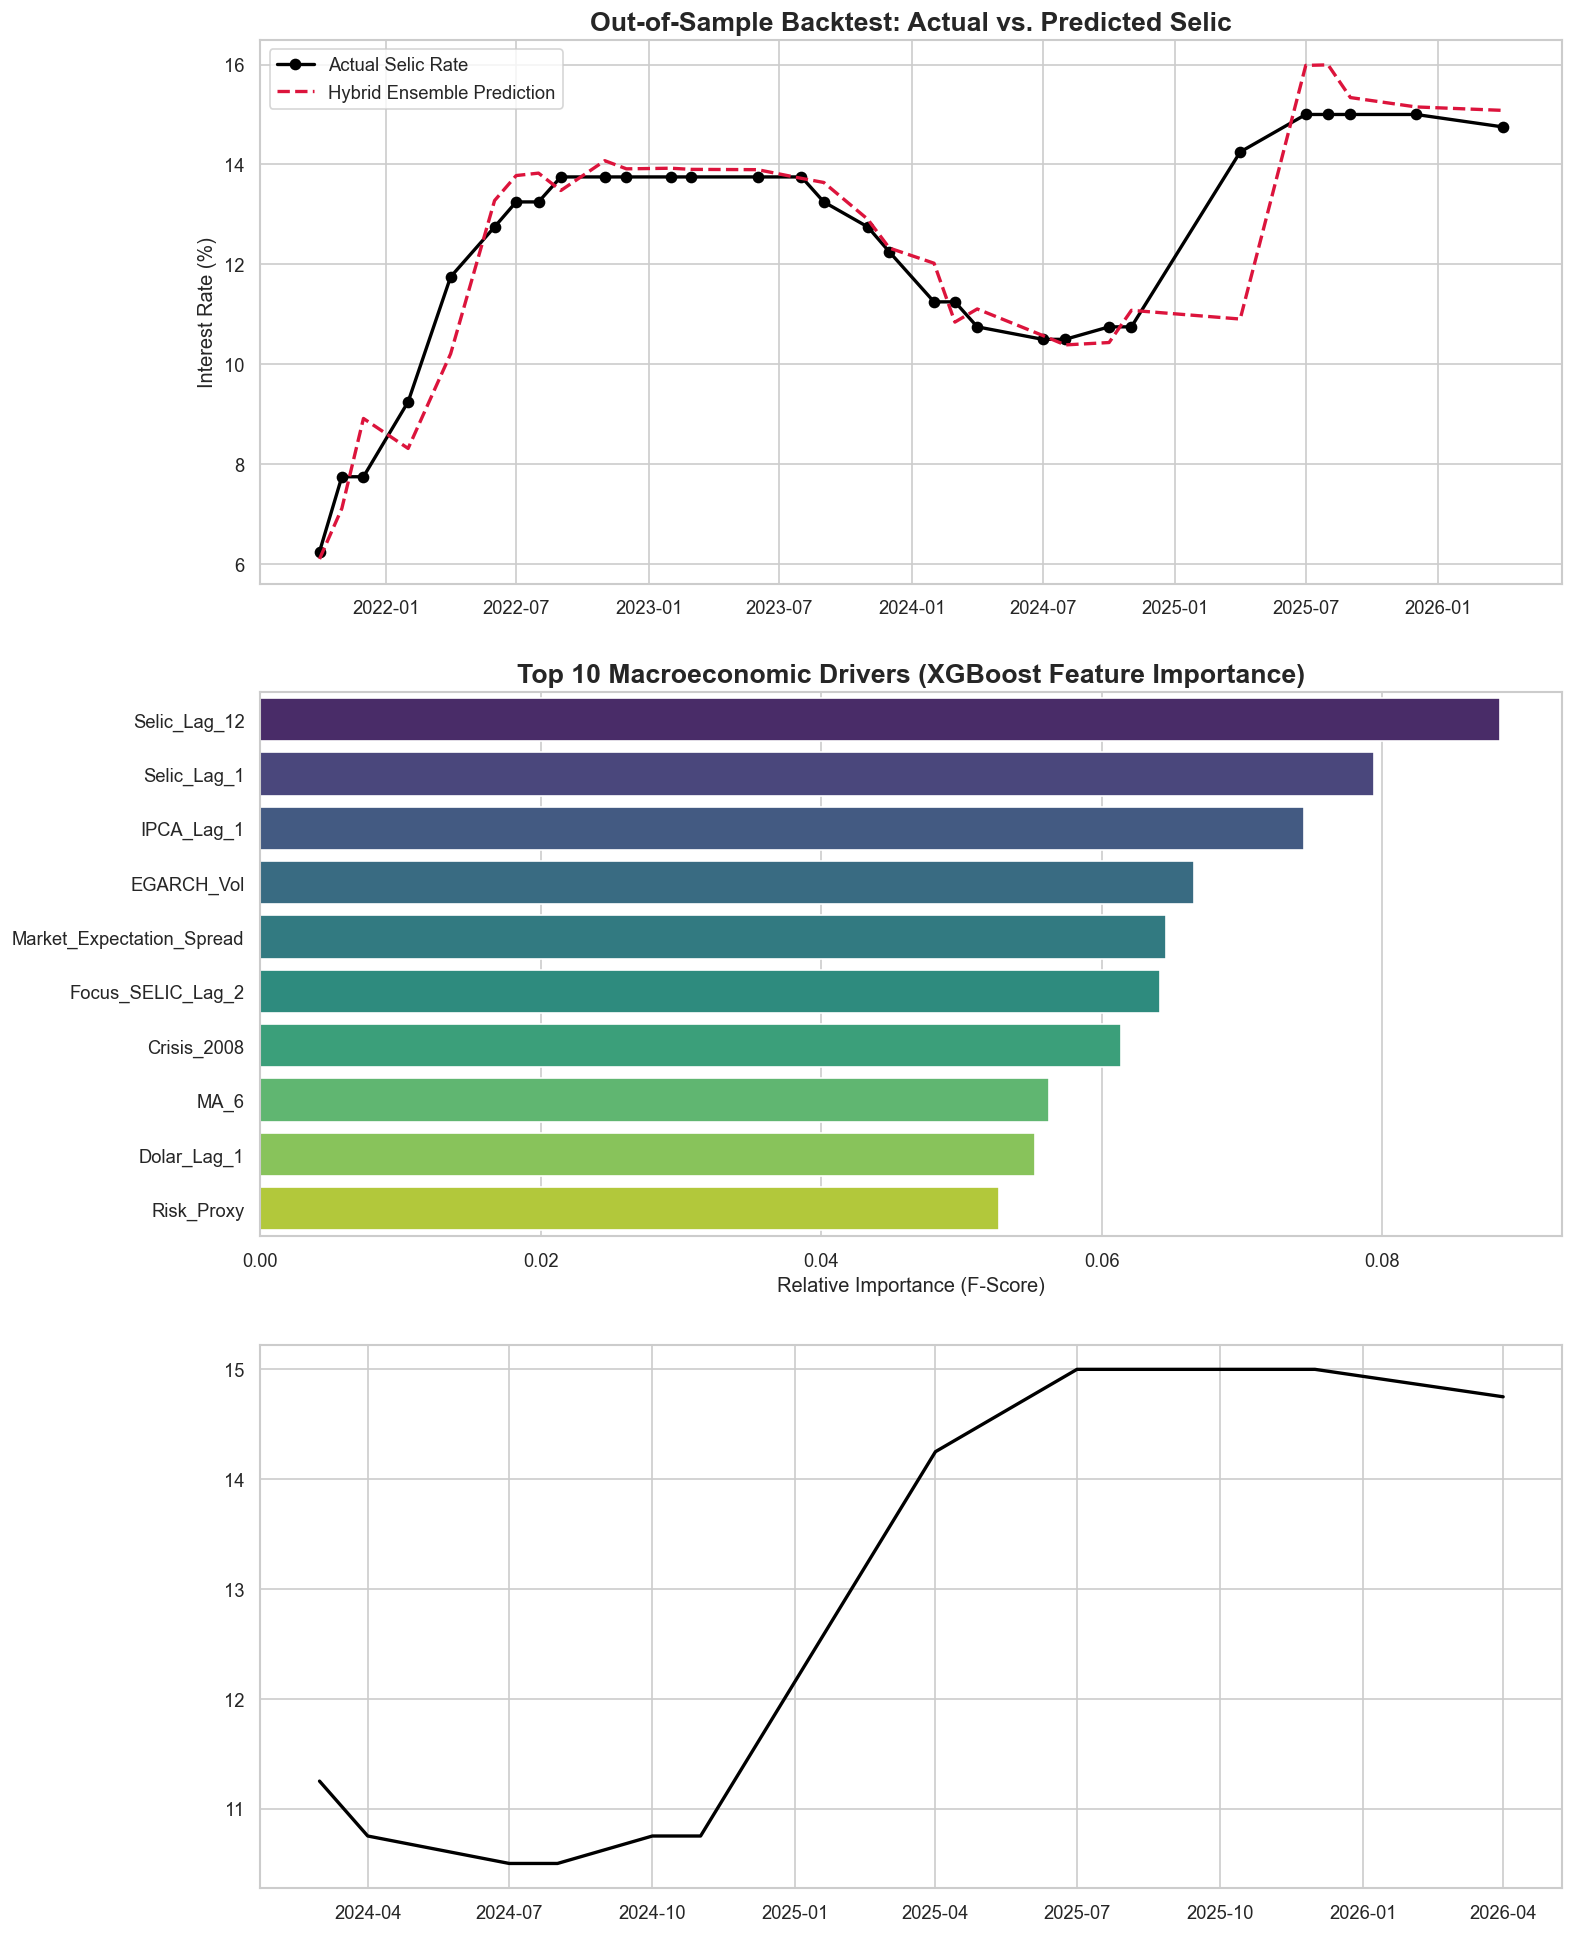

In [18]:
# === Graphical & Statistical Visualizations ===

import matplotlib.pyplot as plt
import seaborn as sns

# Set a professional institutional aesthetic
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 12, 'figure.dpi': 120})

fig, axes = plt.subplots(3, 1, figsize=(14, 20))

# ---------------------------------------------------------
# Plot 1: Out-of-Sample Fit (Test Set: Actual vs Ensemble)
# ---------------------------------------------------------
axes[0].plot(y_test_actual_selic.index, y_test_actual_selic.values, label='Actual Selic Rate', color='black', linewidth=2, marker='o')
axes[0].plot(y_test_actual_selic.index, y_pred_ensemble.values, label='Hybrid Ensemble Prediction', color='crimson', linewidth=2, linestyle='--')
axes[0].set_title('Out-of-Sample Backtest: Actual vs. Predicted Selic', fontsize=16, fontweight='bold')
axes[0].set_ylabel('Interest Rate (%)')
axes[0].legend(loc='best')

# ---------------------------------------------------------
# Plot 2: Feature Importance (Demystifying the XGBoost)
# ---------------------------------------------------------
# Extract importances from the residual model to show what drives the model's alpha
importances = xgb_residual_model.feature_importances_
feature_names = X_train.columns
feat_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances}).sort_values(by='Importance', ascending=False)

sns.barplot(x='Importance', y='Feature', data=feat_imp_df.head(10), ax=axes[1], palette='viridis')
axes[1].set_title('Top 10 Macroeconomic Drivers (XGBoost Feature Importance)', fontsize=16, fontweight='bold')
axes[1].set_xlabel('Relative Importance (F-Score)')
axes[1].set_ylabel('')

# ---------------------------------------------------------
# Plot 3: Future Forecast Fan Chart (Scenarios & COPOM Dates)
# ---------------------------------------------------------
# Concatenate the last known actual data with the future forecast for a continuous line
historical_dates = df_model_clean.index[-12:]
historical_rates = df_model_clean['Selic_Meta'].iloc[-12:]

# Combine historical and future meeting dates
all_dates = list(historical_dates) + meeting_dates
base_line = list(historical_rates) + list(baseline)

axes[2].plot(historical_dates, historical_rates, label='Historical Selic', color='black', linewidth=2)
axes[2].plot(meeting_dates, baseline, label='Base Forecast', color='blue', linewidth=2, marker='o')

# Create the confidence bands (Fan Chart) using the scenarios calculated in Cell 15
axes[2].fill_between(meeting_dates, low_scenario, high_scenario, color='blue', alpha=0.15, label='Volatility Band (±1.5σ EGARCH)')

# Add a red dashed line representing the "Market Consensus" (14.00%) for visual divergence
axes[2].axhline(y=14.0, color='red', linestyle='--', alpha=0.7, label='Market Consensus View (14.00%)')

axes[2].set_title('Forward-Looking Selic Rate Projection & Risk Scenarios', fontsize=16, fontweight='bold')
axes[2].set_ylabel('Interest Rate (%)')
axes[2].legend(loc='lower left')

plt.tight_layout()
plt.show()

In [ ]:
# === LSTM Model for Forecasting the Selic Rate ===
'''
import optuna 
from tensorflow.keras.models import Sequential #type: ignore
from tensorflow.keras.layers import LSTM, Dense, Dropout #type: ignore
from sklearn.preprocessing import MinMaxScaler 

def create_sequences(data, n_steps=12):
    X, y = [], []
    for i in range(n_steps, len(data)):
        X.append(data[i-n_steps:i, 0])  # features
        y.append(data[i, 0])            # target
    return np.array(X), np.array(y)

serie_selic = df_final['Selic_Meta'].values

# Normalize the data between 0 and 1 and create the sequence for LTSM Neural Network Model
# LTSM models are RNNs Machine Learning models

scaler = MinMaxScaler(feature_range=(0, 1))

scaled_data = scaler.fit_transform(serie_selic.reshape(-1, 1))
n_steps = 12
X, y = create_sequences(scaled_data, n_steps)

split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# === Developing the LSTM Model ===
model_lstm = Sequential([
    LSTM(50, return_sequences=True, input_shape=(n_steps, 1)),
    Dropout(0.2),
    LSTM(50, return_sequences=False),
    Dropout(0.2),
    Dense(25),
    Dense(1)
])

model_lstm.compile(optimizer='adam', loss='mse')

history = model_lstm.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_test, y_test), verbose=1)

#Prediction for the last 12 months using the LSTM model
print('Running Model...')

last_sequence = scaled_data[-n_steps:].reshape((1, n_steps, 1))
predictions_scaled = []
for _ in range(12):
    pred = model_lstm.predict(last_sequence, verbose=0)
    predictions_scaled.append(pred[0, 0])

    # Update the last_sequence with the new prediction
    last_sequence = np.append(last_sequence[:, 1:, :], pred.reshape(1, 1, 1), axis=1)

# Denormalize the predictions

predictions_lstm = scaler.inverse_transform(np.array(predictions_scaled).reshape(-1, 1))
print("\nPrediction LSTM (12 months):")
print(predictions_lstm.flatten())
'''

# The LSTM model will be substituted by a more robust ML Model: XGBoost (Decision Tree Model). 
# XGBoost will be optimized with Optuna Hyperparameter 

'\nimport optuna \nfrom tensorflow.keras.models import Sequential #type: ignore\nfrom tensorflow.keras.layers import LSTM, Dense, Dropout #type: ignore\nfrom sklearn.preprocessing import MinMaxScaler \n\ndef create_sequences(data, n_steps=12):\n    X, y = [], []\n    for i in range(n_steps, len(data)):\n        X.append(data[i-n_steps:i, 0])  # features\n        y.append(data[i, 0])            # target\n    return np.array(X), np.array(y)\n\nserie_selic = df_final[\'Selic_Meta\'].values\n\n# Normalize the data between 0 and 1 and create the sequence for LTSM Neural Network Model\n# LTSM models are RNNs Machine Learning models\n\nscaler = MinMaxScaler(feature_range=(0, 1))\n\nscaled_data = scaler.fit_transform(serie_selic.reshape(-1, 1))\nn_steps = 12\nX, y = create_sequences(scaled_data, n_steps)\n\nsplit = int(0.8 * len(X))\nX_train, X_test = X[:split], X[split:]\ny_train, y_test = y[:split], y[split:]\n\nX_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))\nX_test = X_t

In [ ]:
# Célula 6: Cenários e Sinal
# Usar a previsão do LSTM como baseline (ou escolha a que tiver melhor erro no teste)
#baseline = predictions_lstm.flatten()  # ou forecast_arima
''''
# Definir a volatilidade prevista (usar a média ou a última estimada)
sigma = np.mean(vol_forecast)  # volatilidade média prevista

# Cenários
#cenario_baixa = baseline - (1.5 * sigma)
#cenario_alta = baseline + (1.5 * sigma)
#cenario_base = baseline

# Exibir cenários
df_cenarios = pd.DataFrame({
    'Mês': list(range(1, 13)),
    #'Base': cenario_base,
    #'Alta (+1.5σ)': cenario_alta,
    #'Baixa (-1.5σ)': cenario_baixa
})
print("--- Cenários de Taxa Selic (próximos 12 meses) ---")
print(df_cenarios)

# --- LÓGICA DO SINAL DE REBALANCEAMENTO (EXEMPLO) ---
# Supondo que a Selic atual seja a última do DataFrame
selic_atual = df_model['Selic_Meta'].iloc[-1]

# Forecast mean for the next 12 months
#media_prevista_12m = np.mean(cenario_base)
#desvio_previsto_12m = np.std(cenario_base)

# Simple rule for rebalancing signal based on the forecasted interest rate and its volatility
#if media_prevista_12m > (selic_atual + 1.0):
#    sinal = "🔴 Reduce Stocks and ETFs positions (Increasing Interest Rates)"
#elif media_prevista_12m < (selic_atual - 1.0):
#    sinal = "🟢 Increase Stocks and ETFs positions (Low interest rate)"
#else:
#    sinal = "🟡 Maintain current position (Stable Interest Rate)"

#print("\n" + "="*50)
#print(f"Actual Selic Interest Rates: {selic_atual:.2f}%")
#print(f"Forecasted Mean (12 months): {media_prevista_12m:.2f}%")
#rint(f"Standard Deviation: {desvio_previsto_12m:.2f}%")
#print(f"\n📊 Rebalanced Mathematical Signal: {sinal}")
#print("="*50)
'''

'\'\n# Definir a volatilidade prevista (usar a média ou a última estimada)\nsigma = np.mean(vol_forecast)  # volatilidade média prevista\n\n# Cenários\n#cenario_baixa = baseline - (1.5 * sigma)\n#cenario_alta = baseline + (1.5 * sigma)\n#cenario_base = baseline\n\n# Exibir cenários\ndf_cenarios = pd.DataFrame({\n    \'Mês\': list(range(1, 13)),\n    #\'Base\': cenario_base,\n    #\'Alta (+1.5σ)\': cenario_alta,\n    #\'Baixa (-1.5σ)\': cenario_baixa\n})\nprint("--- Cenários de Taxa Selic (próximos 12 meses) ---")\nprint(df_cenarios)\n\n# --- LÓGICA DO SINAL DE REBALANCEAMENTO (EXEMPLO) ---\n# Supondo que a Selic atual seja a última do DataFrame\nselic_atual = df_model[\'Selic_Meta\'].iloc[-1]\n\n# Forecast mean for the next 12 months\n#media_prevista_12m = np.mean(cenario_base)\n#desvio_previsto_12m = np.std(cenario_base)\n\n# Simple rule for rebalancing signal based on the forecasted interest rate and its volatility\n#if media_prevista_12m > (selic_atual + 1.0):\n#    sinal = "🔴 Reduc